In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "data").exists():
    ROOT_DIR = ROOT_DIR.parent

DATA_PATH = ROOT_DIR / "data" / "sample" / "sales_events.jsonl"

sales = pd.read_json(DATA_PATH, lines=True)
sales["event_timestamp"] = pd.to_datetime(sales["event_timestamp"])

sales.head()

Matplotlib is building the font cache; this may take a moment.


,event_id,event_timestamp,order_id,customer_id,store_id,region,product_id,category,quantity,unit_price,total_amount
0,2cb09ae6-c4c6-4352-85b7-b0310440f34e,2026-10-12 16:00:36.289998+00:00,ORD42098,CUST4657,STR001,Midwest,PRD002,Electronics,3,149.99,449.97
1,d5139a47-c075-43e0-9802-b46f5c820051,2026-10-12 16:00:36.290206+00:00,ORD87397,CUST7912,STR001,Midwest,PRD003,Home,1,49.99,49.99
2,35d3f3a2-a710-45d7-b047-3fb1ffc5b075,2026-10-12 16:00:36.290213+00:00,ORD38657,CUST4811,STR001,Midwest,PRD001,Electronics,1,79.99,79.99
3,b04f4803-bdd2-435c-b25b-3517c1806c68,2026-10-12 16:00:36.290223+00:00,ORD95181,CUST9928,STR005,West,PRD001,Electronics,2,79.99,159.98
4,3fb8f3f6-34a1-4ecd-9188-43ec5ddf67ac,2026-10-12 16:00:36.290228+00:00,ORD87236,CUST5557,STR002,Midwest,PRD007,Apparel,4,64.99,259.96


In [2]:
print("Total sales events:", len(sales))
print("Missing values:")
print(sales.isna().sum())

print("\nSales by category:")
print(sales.groupby("category")["total_amount"].sum().sort_values(ascending=False))

print("\nSales by region:")
print(sales.groupby("region")["total_amount"].sum().sort_values(ascending=False))

Total sales events: 1000
Missing values:
event_id           0
event_timestamp    0
order_id           0
customer_id        0
store_id           0
region             0
product_id         0
category           0
quantity           0
unit_price         0
total_amount       0
dtype: int64

Sales by category:
category
Electronics    75523.56
Sports         40103.27
Apparel        25884.14
Home           21183.80
Name: total_amount, dtype: float64

Sales by region:
region
Midwest    91970.59
South      36404.50
West       34319.68
Name: total_amount, dtype: float64


In [3]:
clean_sales = (
    sales.drop_duplicates(subset="event_id")
    .dropna(subset=["total_amount", "quantity", "unit_price", "category", "region"])
)

clean_sales = clean_sales[
    (clean_sales["total_amount"] > 0)
    & (clean_sales["quantity"] > 0)
    & (clean_sales["unit_price"] > 0)
]

print("Records before cleaning:", len(sales))
print("Records after cleaning:", len(clean_sales))

Records before cleaning: 1000
Records after cleaning: 1000


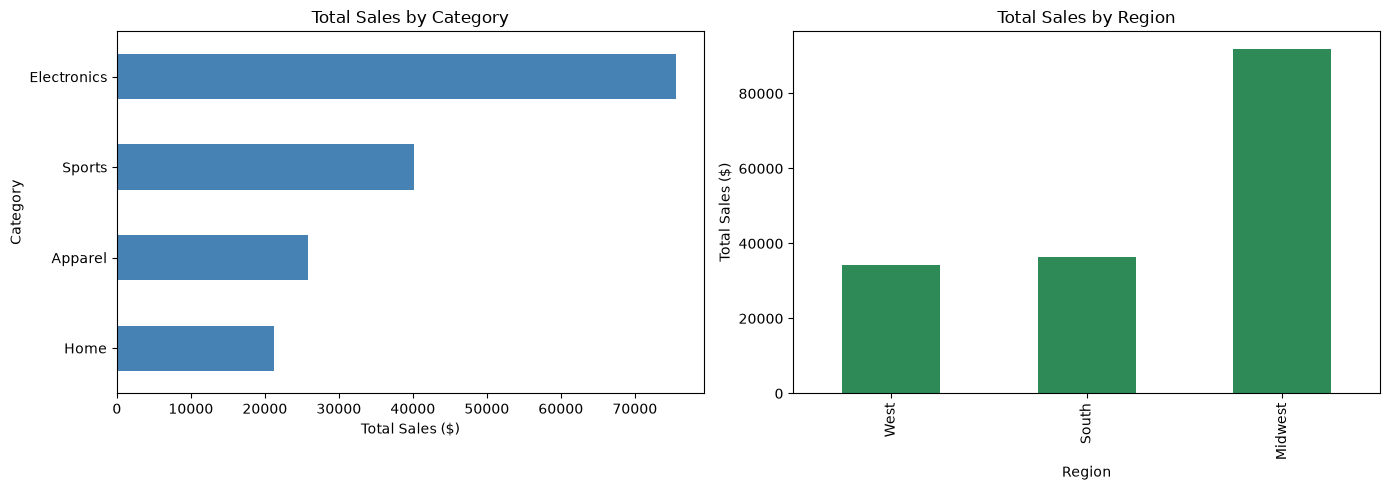

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

category_sales = clean_sales.groupby("category")["total_amount"].sum().sort_values()
category_sales.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Total Sales by Category")
axes[0].set_xlabel("Total Sales ($)")
axes[0].set_ylabel("Category")

region_sales = clean_sales.groupby("region")["total_amount"].sum().sort_values()
region_sales.plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Total Sales by Region")
axes[1].set_ylabel("Total Sales ($)")
axes[1].set_xlabel("Region")

plt.tight_layout()
plt.show()

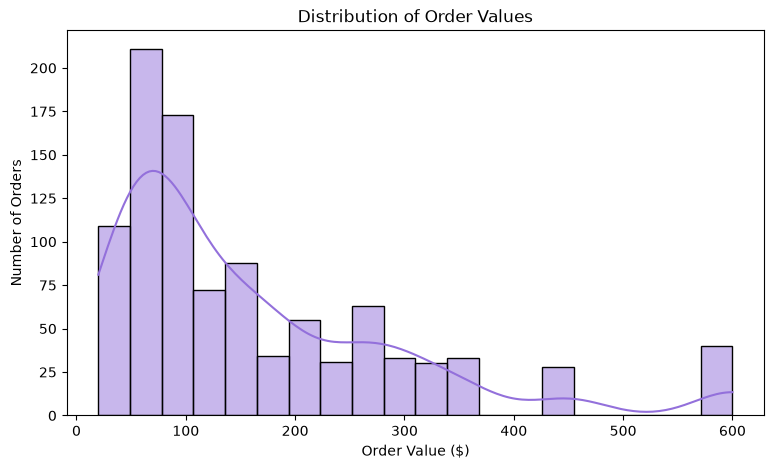

In [5]:
plt.figure(figsize=(9, 5))

sns.histplot(clean_sales["total_amount"], bins=20, kde=True, color="mediumpurple")

plt.title("Distribution of Order Values")
plt.xlabel("Order Value ($)")
plt.ylabel("Number of Orders")
plt.show()

In [6]:
top_category = clean_sales.groupby("category")["total_amount"].sum().idxmax()
top_region = clean_sales.groupby("region")["total_amount"].sum().idxmax()
average_order_value = clean_sales["total_amount"].mean()

print("Top sales category:", top_category)
print("Top sales region:", top_region)
print("Average order value: $", round(average_order_value, 2))

Top sales category: Electronics
Top sales region: Midwest
Average order value: $ 162.69


## Key Findings

- The dataset contains 1,000 clean synthetic retail sales events.
- Electronics generated the highest total sales among product categories.
- The Midwest generated the highest total sales among regions.
- The average order value was $162.69.

In [7]:
from scipy.stats import ttest_ind

midwest_orders = clean_sales.loc[
    clean_sales["region"] == "Midwest", "total_amount"
]

west_orders = clean_sales.loc[
    clean_sales["region"] == "West", "total_amount"
]

t_statistic, p_value = ttest_ind(
    midwest_orders,
    west_orders,
    equal_var=False,
)

print("Midwest average order value: $", round(midwest_orders.mean(), 2))
print("West average order value: $", round(west_orders.mean(), 2))
print("P-value:", round(p_value, 4))

Midwest average order value: $ 158.57
West average order value: $ 165.0
P-value: 0.5482


## Hypothesis Test

I tested whether Midwest and West orders had different average order values.

- Midwest average order value: $158.57
- West average order value: $165.00
- P-value: 0.5482

Because the p-value is greater than 0.05, there is not enough evidence in this synthetic dataset to conclude that Midwest and West order values are meaningfully different.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

high_value_threshold = clean_sales["total_amount"].median()

model_data = clean_sales.copy()
model_data["high_value_order"] = (
    model_data["total_amount"] > high_value_threshold
).astype(int)

X = model_data[["quantity", "unit_price", "category", "region"]]
y = model_data["high_value_order"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

preprocessor = ColumnTransformer(
    transformers=[
        ("category_region", OneHotEncoder(handle_unknown="ignore"), ["category", "region"]),
    ],
    remainder="passthrough",
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("High-value threshold: $", round(high_value_threshold, 2))
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("Precision:", round(precision_score(y_test, predictions), 3))
print("Recall:", round(recall_score(y_test, predictions), 3))

High-value threshold: $ 119.96
Accuracy: 1.0
Precision: 1.0
Recall: 1.0


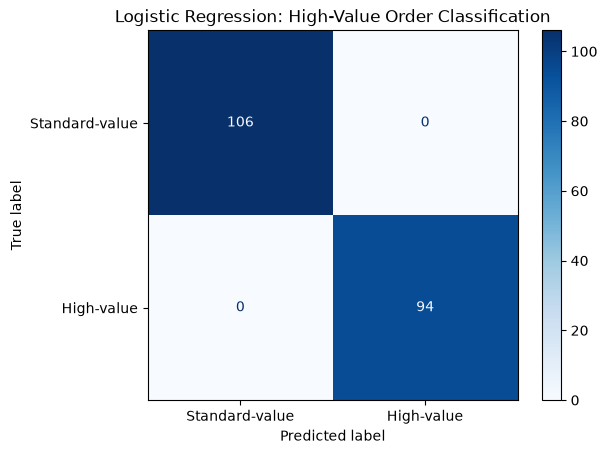

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Standard-value", "High-value"],
    cmap="Blues",
)

plt.title("Logistic Regression: High-Value Order Classification")
plt.show()

## Logistic Regression Model

I built a Logistic Regression model to classify orders as high-value or standard-value.

- High-value threshold: $119.96
- Accuracy: 1.00
- Precision: 1.00
- Recall: 1.00

This result is from synthetic data. The model uses quantity and unit price, which are closely related to total order value, so the perfect score should not be treated as real-world predictive performance.